# Module 3: How Encoders and Decoders Work in Multimodal Foundation Models

Almost every foundation model is built from two kinds of parts:

- an **encoder**, which turns raw input (a load curve, an image, a sentence) into a list of numbers called an **embedding**;
- a **decoder**, which turns an embedding back into an output (a load curve, a sentence, ...).

**Multimodal** models combine several input types ("modalities"), for example images and text,
by giving each its own encoder and making their embeddings comparable.

**Learning goals**

- **Part A:** build a tiny encoder–decoder yourself on Swiss daily electricity load profiles, and follow the data shape step by step.
- **Part B:** see how **CLIP** maps satellite images and text into one **shared embedding space**, and use it to classify land use without training.
- **Part C:** see how **BLIP** uses an image encoder plus a text **decoder** to generate a caption word by word, and where it fails.

**Runs locally** in the `fm4ues` conda environment (see the repository README). A GPU is used when available.
Every main step is timed, and a runtime summary is shown at the end.

## 0. Setup and GPU check

In [1]:
import io
import time
import platform
import logging
import warnings
from contextlib import contextmanager
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import transformers

# Keep the output tidy: hide progress bars, a harmless Windows-only PyTorch notice and library warnings
transformers.utils.logging.disable_progress_bar()
transformers.utils.logging.set_verbosity_error()
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")

# Repository root = the first parent folder that contains requirements.txt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
CACHE = ROOT / "data" / "cache"          # downloaded data goes here (ignored by git)
CACHE.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() and torch.cuda.device_count() > 0 else "cpu"
# DEVICE = "cpu"   # <- uncomment to compare with CPU speed
print(f"Python  : {platform.python_version()}")
print(f"PyTorch : {torch.__version__}")
print(f"Device  : {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))
print(f"Data dir: {CACHE.relative_to(ROOT)}")

np.random.seed(0)
torch.manual_seed(0)

# --- Timing helper -------------------------------------------------------
TIMINGS = {}  # step name -> seconds

@contextmanager
def timed(step):
    # Measure the wall-clock time of a block of code and store it in TIMINGS.
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    yield
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    TIMINGS[step] = time.perf_counter() - start
    print(f"[time] {step}: {TIMINGS[step]:.1f} s")

plt.rcParams["figure.figsize"] = (12, 4)

Python  : 3.11.18
PyTorch : 2.11.0+cu128
Device  : cuda (Quadro RTX 6000)
Data dir: data\cache


## 1. The big picture

```
            ENCODER                    EMBEDDING                 DECODER
 raw input ─────────► a short list of numbers (a "vector") ─────────► output
 (24 hourly loads,     that summarises the input             (24 hourly loads,
  an image, a text)    e.g. 2, 512 or 768 numbers             a caption, ...)
```

- The **embedding** is the model's internal "summary". Similar inputs get similar embeddings (close together).
- An **encoder-only** model (like CLIP) is used to compare, search and classify.
- An **encoder–decoder** model (like BLIP, or the autoencoder in Part A) also generates an output from the embedding.
- In a **multimodal** model, each modality has its own encoder, trained so that matching inputs
  (an image and its description) end up with similar embeddings: a **shared embedding space**.

## Part A: Build a tiny encoder–decoder (autoencoder) for daily load profiles

An **autoencoder** is the simplest encoder–decoder: the encoder squeezes the input into a very small embedding,
and the decoder must rebuild the original input from it. To succeed, the embedding has to capture
the most important features of the input. Nobody tells the model what those features are; it learns them.

We use the Swiss hourly electricity demand from Module 1, cut into **days of 24 hours** (in Swiss local time).
Each day is divided by its own average, so the model sees the **shape** of the day (morning ramp,
midday dip, evening peak), not the absolute level.

[time] 1. Load electricity demand (download on first run): 0.1 s
1726 daily profiles, each with 24 hourly values


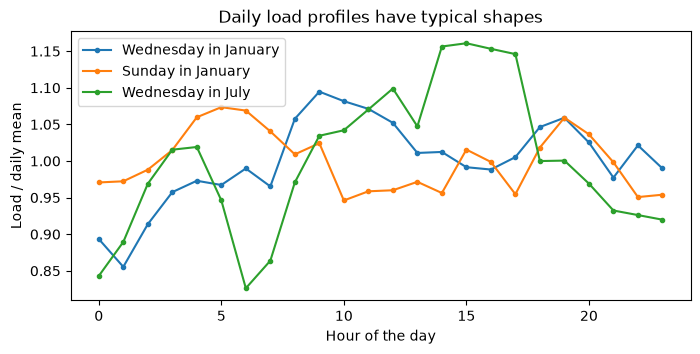

In [2]:
OPSD_URL = "https://data.open-power-system-data.org/time_series/2020-10-06/time_series_60min_singleindex.csv"
LOAD_COL = "CH_load_actual_entsoe_transparency"
LOAD_FILE = CACHE / "opsd_ch_load.csv"            # same file as Module 1

with timed("1. Load electricity demand (download on first run)"):
    if not LOAD_FILE.exists():
        print("Downloading OPSD data (~130 MB, only needed once) ...")
        pd.read_csv(OPSD_URL, usecols=["utc_timestamp", LOAD_COL]).to_csv(LOAD_FILE, index=False)
    load = pd.read_csv(LOAD_FILE, index_col="utc_timestamp")[LOAD_COL]
    load.index = pd.to_datetime(load.index, utc=True).tz_convert("Europe/Zurich")   # Swiss local time
    load = load.loc["2016-01-01":"2020-09-30"]

# One row per day, one column per hour; drop daylight-saving days (23 or 25 hours) and days with gaps
frame = pd.DataFrame({"load": load.values, "date": load.index.date, "hour": load.index.hour})
frame = frame[~frame.duplicated(["date", "hour"], keep=False)]      # removes the repeated hour in October
days = frame.pivot(index="date", columns="hour", values="load").dropna()
days.index = pd.to_datetime(days.index)

profiles = days.div(days.mean(axis=1), axis=0)                     # shape only: each day averages to 1.0
print(f"{len(profiles)} daily profiles, each with {profiles.shape[1]} hourly values")

plt.figure(figsize=(8, 3.5))
for d, label in [("2019-01-16", "Wednesday in January"), ("2019-01-20", "Sunday in January"),
                 ("2019-07-17", "Wednesday in July")]:
    plt.plot(profiles.loc[d].values, marker=".", label=label)
plt.xlabel("Hour of the day")
plt.ylabel("Load / daily mean")
plt.title("Daily load profiles have typical shapes")
plt.legend()
plt.show()

### The model

The encoder compresses **24 numbers to 2**, and the decoder expands **2 numbers back to 24**.
We choose a 2-number embedding on purpose, so that we can draw it on a flat plot.

In [3]:
EMBED_DIM = 2

encoder = nn.Sequential(          # 24 -> 16 -> 2
    nn.Linear(24, 16), nn.Tanh(),
    nn.Linear(16, EMBED_DIM),
)
decoder = nn.Sequential(          # 2 -> 16 -> 24
    nn.Linear(EMBED_DIM, 16), nn.Tanh(),
    nn.Linear(16, 24),
)
autoencoder = nn.Sequential(encoder, decoder).to(DEVICE)

# Standardise each hour (subtract its average, divide by its spread) using the training years only.
# Neural networks learn much better when inputs vary around 0 instead of all sitting near 1.0.
train_years = profiles.index.year <= 2018
HOUR_MEAN = profiles[train_years].mean().values
HOUR_STD = profiles[train_years].std().values
to_model = lambda p: torch.tensor((np.asarray(p) - HOUR_MEAN) / HOUR_STD, dtype=torch.float32, device=DEVICE)
from_model = lambda t: t.detach().cpu().numpy() * HOUR_STD + HOUR_MEAN      # back to "load / daily mean"

# Trace the data shape through the model, using 5 example days
x = to_model(profiles.values[:5])
z = encoder.to(DEVICE)(x)
x_hat = decoder.to(DEVICE)(z)
print(f"input      : {tuple(x.shape)}   (5 days x 24 hours)")
print(f"embedding  : {tuple(z.shape)}    (5 days x {EMBED_DIM} numbers)  <- the 'summary' of each day")
print(f"output     : {tuple(x_hat.shape)}   (5 days x 24 hours, rebuilt from the embedding)")
print(f"parameters : {sum(p.numel() for p in autoencoder.parameters())} (a large FM has hundreds of millions)")

input      : (5, 24)   (5 days x 24 hours)
embedding  : (5, 2)    (5 days x 2 numbers)  <- the 'summary' of each day
output     : (5, 24)   (5 days x 24 hours, rebuilt from the embedding)
parameters : 890 (a large FM has hundreds of millions)


### Training

Training adjusts the parameters so that the output looks as much as possible like the input.
The error measure is the mean squared difference ("reconstruction loss"). We train on 2016–2018 and keep 2019–2020 for testing.

[time] 2. Train autoencoder (3,000 steps): 11.4 s
Test reconstruction error (RMSE): 0.035 x daily mean, i.e. about 3.5% of the average load


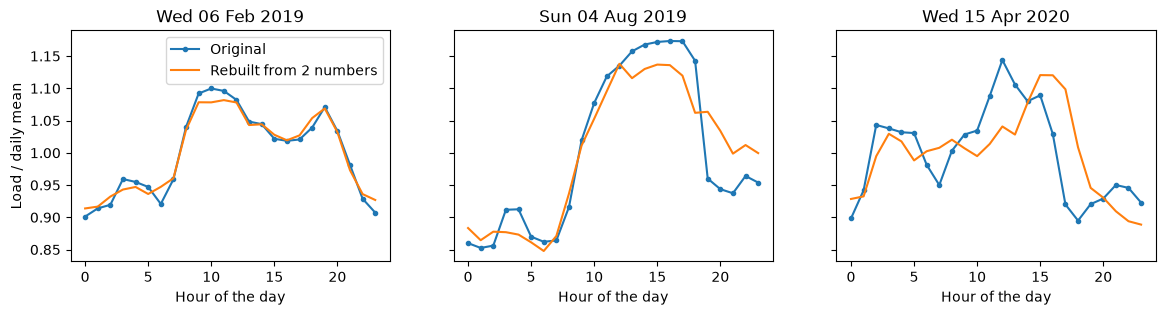

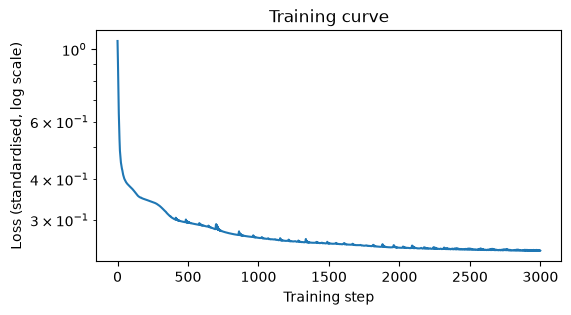

In [4]:
train = to_model(profiles[train_years].values)
test = to_model(profiles[~train_years].values)

optimizer = torch.optim.Adam(autoencoder.parameters(), lr=1e-2)
loss_fn = nn.MSELoss()
history = []

with timed("2. Train autoencoder (3,000 steps)"):
    for step in range(3000):
        optimizer.zero_grad()
        loss = loss_fn(autoencoder(train), train)   # compare output with input
        loss.backward()                              # compute how to change each parameter
        optimizer.step()                             # change the parameters a little
        history.append(loss.item())

# Reconstruction error on the test years, converted back to the original units (load / daily mean)
with torch.no_grad():
    rebuilt = from_model(autoencoder(test))
rmse = np.sqrt(((rebuilt - profiles[~train_years].values) ** 2).mean())
print(f"Test reconstruction error (RMSE): {rmse:.3f} x daily mean, i.e. about {100 * rmse:.1f}% of the average load")

# Compare a few test days with their reconstruction
fig, axes = plt.subplots(1, 3, figsize=(14, 3), sharey=True)
for ax, d in zip(axes, ["2019-02-06", "2019-08-04", "2020-04-15"]):
    i = profiles.index.get_loc(pd.Timestamp(d))
    ax.plot(profiles.values[i], marker=".", label="Original")
    ax.plot(from_model(autoencoder(to_model(profiles.values[i:i + 1])))[0], label="Rebuilt from 2 numbers")
    ax.set_title(f"{pd.Timestamp(d):%a %d %b %Y}")
    ax.set_xlabel("Hour of the day")
axes[0].set_ylabel("Load / daily mean")
axes[0].legend()
plt.show()

plt.figure(figsize=(6, 3))
plt.semilogy(history)
plt.xlabel("Training step"); plt.ylabel("Loss (standardised, log scale)"); plt.title("Training curve")
plt.show()

### What did the encoder learn?

Each day is now a point in a 2-D **embedding space**. We never told the model about weekdays or seasons,
yet similar days should end up close together.

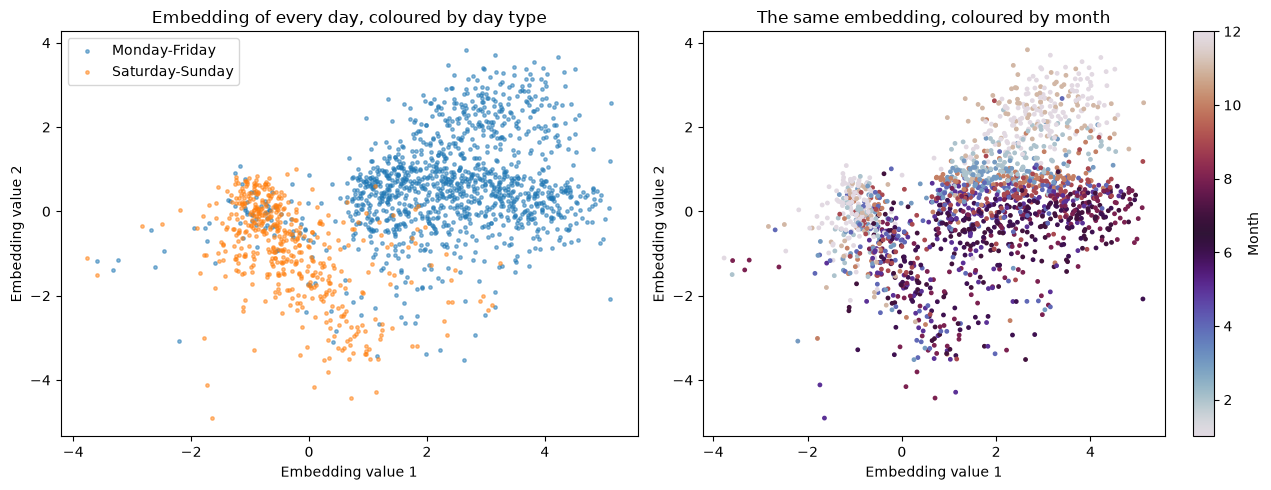

In [5]:
with torch.no_grad():
    emb = encoder(to_model(profiles.values)).cpu().numpy()

is_weekend = profiles.index.dayofweek >= 5
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(emb[~is_weekend, 0], emb[~is_weekend, 1], s=6, alpha=0.5, label="Monday-Friday")
axes[0].scatter(emb[is_weekend, 0], emb[is_weekend, 1], s=6, alpha=0.5, label="Saturday-Sunday")
axes[0].set_title("Embedding of every day, coloured by day type")
axes[0].legend()
sc = axes[1].scatter(emb[:, 0], emb[:, 1], s=6, c=profiles.index.month, cmap="twilight")
fig.colorbar(sc, ax=axes[1], label="Month")
axes[1].set_title("The same embedding, coloured by month")
for ax in axes:
    ax.set_xlabel("Embedding value 1"); ax.set_ylabel("Embedding value 2")
plt.tight_layout()
plt.show()

Working days and weekends separate clearly, and the season changes gradually across the space.
The encoder discovered these patterns by itself,
because they are the most useful information for rebuilding a day's shape.

### The decoder as a generator

The decoder can turn **any** point of the embedding space into a load profile, even points that belong to no real day.
This is the core idea behind generative models: pick an embedding, decode it, get a new, realistic-looking output.
Below we decode points along a straight line between a typical working day and a typical Sunday.

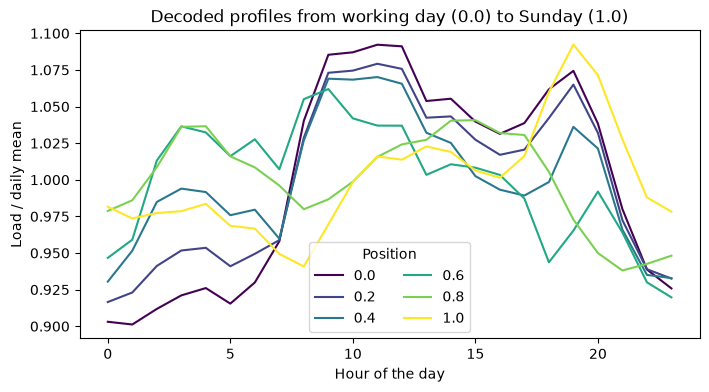

In [6]:
start = emb[(~is_weekend) & (profiles.index.month == 1)].mean(axis=0)    # average January working day
end = emb[(profiles.index.dayofweek == 6) & (profiles.index.month == 1)].mean(axis=0)   # average January Sunday
steps = np.linspace(0, 1, 6)
path = torch.tensor(np.array([start + s * (end - start) for s in steps]), dtype=torch.float32, device=DEVICE)

with torch.no_grad():
    generated = from_model(decoder(path))

plt.figure(figsize=(8, 4))
colors = plt.cm.viridis(steps)
for s, g, c in zip(steps, generated, colors):
    plt.plot(g, color=c, label=f"{s:.1f}")
plt.xlabel("Hour of the day"); plt.ylabel("Load / daily mean")
plt.title("Decoded profiles from working day (0.0) to Sunday (1.0)")
plt.legend(title="Position", ncol=2)
plt.show()

The two ends look like real days: a working day with a steep morning ramp and a midday plateau,
and a winter Sunday with a late start and an evening peak. The profiles **in between** can look less natural.
The straight line passes through a part of the embedding space where few real days lie, so the decoder
has little experience there. Keep this in mind: **a decoder is only reliable where it has seen training data.**
We will meet the same effect in Part C.

## Part B: Two encoders, one shared space (CLIP)

**CLIP** (OpenAI, 2021) has two encoders that were trained together on 400 million image–caption pairs from the internet:

- an **image encoder** (a Vision Transformer) that turns an image into 512 numbers;
- a **text encoder** (a Transformer) that turns a sentence into 512 numbers.

Training pushed each image's embedding **close to the embedding of its own caption** and away from all other captions.
The result is a shared space where "a picture of a forest" and the text "a forest" point in a similar direction.

That makes **zero-shot classification** possible: encode the image, encode one sentence per class,
and pick the class whose sentence is most similar. No training on your images is needed.

**Data:** [EuroSAT](https://github.com/phelber/EuroSAT) (MIT licence): 64 × 64-pixel Sentinel-2 satellite images of Europe
in 10 land-use classes, including *Residential*, *Industrial* and *Highway*. We use the 5,400-image test split.

[time] 3. Load EuroSAT images (download on first run): 1.9 s
5400 images of 64x64 pixels, 10 classes:
{'SeaLake': 609, 'Forest': 608, 'AnnualCrop': 596, 'HerbaceousVegetation': 573, 'Residential': 554, 'PermanentCrop': 538, 'River': 529, 'Industrial': 501, 'Highway': 496, 'Pasture': 396}


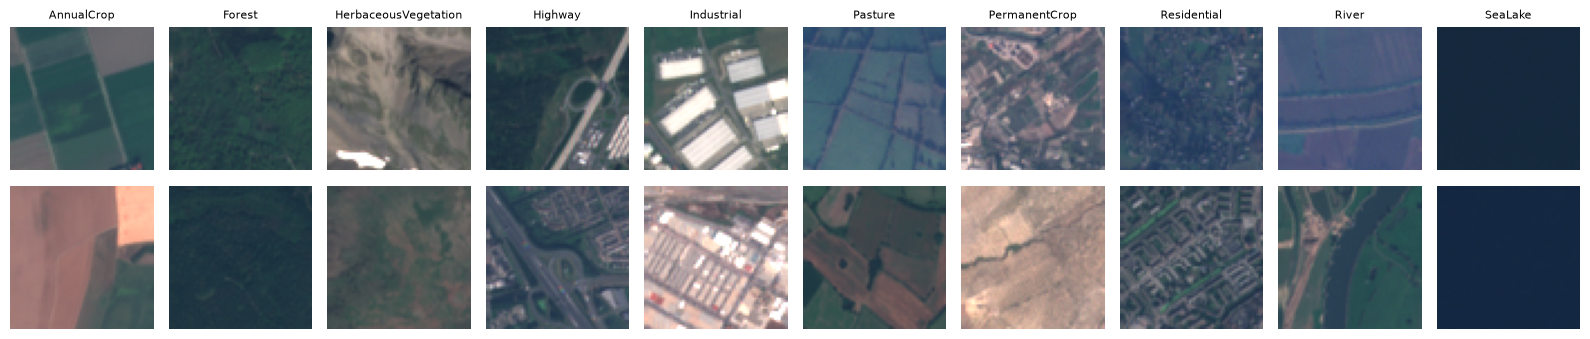

In [7]:
from huggingface_hub import hf_hub_download
from PIL import Image

with timed("3. Load EuroSAT images (download on first run)"):
    path = hf_hub_download("blanchon/EuroSAT_RGB", "data/test-00000-of-00001.parquet", repo_type="dataset")
    eurosat = pd.read_parquet(path)
    eurosat["label"] = eurosat["filename"].str.split("_").str[0]          # e.g. "Residential_123.tif"
    images = [Image.open(io.BytesIO(b["bytes"])).convert("RGB") for b in eurosat["image"]]

CLASSES = sorted(eurosat["label"].unique())
print(f"{len(images)} images of {images[0].size[0]}x{images[0].size[1]} pixels, {len(CLASSES)} classes:")
print(eurosat["label"].value_counts().to_dict())

fig, axes = plt.subplots(2, 10, figsize=(16, 3.6))
for j, cls in enumerate(CLASSES):
    idx = eurosat.index[eurosat["label"] == cls][:2]
    for i, k in enumerate(idx):
        axes[i, j].imshow(images[k]); axes[i, j].axis("off")
    axes[0, j].set_title(cls, fontsize=8)
plt.tight_layout()
plt.show()

In [8]:
from transformers import CLIPModel, CLIPProcessor

with timed("4. Load CLIP (download on first run)"):
    clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEVICE).eval()
    clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

# Trace one image through the image encoder
pixels = clip_proc(images=images[:1], return_tensors="pt")["pixel_values"].to(DEVICE)
with torch.no_grad():
    vision_out = clip.vision_model(pixel_values=pixels)
    image_emb = clip.get_image_features(pixel_values=pixels).pooler_output
print(f"image pixels      : {tuple(pixels.shape)}  (1 image, 3 colours, resized to 224x224)")
print(f"vision tokens     : {tuple(vision_out.last_hidden_state.shape)}  (the image is cut into 7x7=49 patches + 1 summary token)")
print(f"image embedding   : {tuple(image_emb.shape)}  (summary token projected into the shared space)")

tokens = clip_proc(text=["a satellite photo of a forest"], return_tensors="pt", padding=True).to(DEVICE)
with torch.no_grad():
    text_emb = clip.get_text_features(**tokens).pooler_output
print(f"text tokens       : {tuple(tokens['input_ids'].shape)}  (1 sentence, split into word pieces)")
print(f"text embedding    : {tuple(text_emb.shape)}  (same size as the image embedding -> directly comparable)")

[time] 4. Load CLIP (download on first run): 2.4 s
image pixels      : (1, 3, 224, 224)  (1 image, 3 colours, resized to 224x224)
vision tokens     : (1, 50, 768)  (the image is cut into 7x7=49 patches + 1 summary token)
image embedding   : (1, 512)  (summary token projected into the shared space)


text tokens       : (1, 8)  (1 sentence, split into word pieces)
text embedding    : (1, 512)  (same size as the image embedding -> directly comparable)


In [9]:
def embed_images(imgs, batch_size=256):
    # Encode all images; return unit-length embeddings (N, 512) on the CPU.
    out = []
    with torch.no_grad():
        for i in range(0, len(imgs), batch_size):
            px = clip_proc(images=imgs[i:i + batch_size], return_tensors="pt")["pixel_values"].to(DEVICE)
            e = clip.get_image_features(pixel_values=px).pooler_output
            out.append((e / e.norm(dim=-1, keepdim=True)).cpu())
    return torch.cat(out)

def embed_texts(texts):
    with torch.no_grad():
        t = clip_proc(text=texts, return_tensors="pt", padding=True).to(DEVICE)
        e = clip.get_text_features(**t).pooler_output
    return (e / e.norm(dim=-1, keepdim=True)).cpu()

with timed("5. CLIP: encode 5,400 images"):
    img_emb = embed_images(images)
print(f"image embeddings: {tuple(img_emb.shape)}")

[time] 5. CLIP: encode 5,400 images: 21.3 s
image embeddings: (5400, 512)


### Zero-shot classification

For each class we write a short description, encode it, and compare it with every image using **cosine similarity**
(how closely two embeddings point in the same direction, from -1 to 1).
The wording of the descriptions matters, so we try three templates.

[time] 6. CLIP: zero-shot classification (3 prompt templates): 0.1 s
{}                                   46.2%
a satellite photo of {}.             38.3%
a centered satellite photo of {}.    40.9%
(random guessing: 10%)


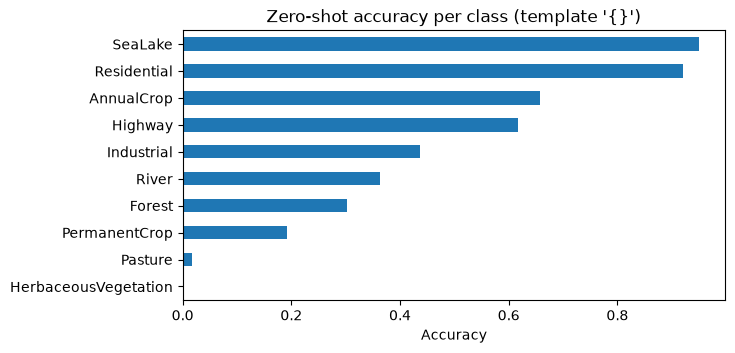

In [10]:
DESCRIPTIONS = {
    "AnnualCrop": "annual crop fields", "Forest": "a forest", "HerbaceousVegetation": "herbaceous vegetation",
    "Highway": "a highway", "Industrial": "industrial buildings", "Pasture": "pasture",
    "PermanentCrop": "permanent crops such as orchards", "Residential": "residential buildings",
    "River": "a river", "SeaLake": "a sea or lake",
}
TEMPLATES = ["{}", "a satellite photo of {}.", "a centered satellite photo of {}."]
truth = eurosat["label"].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()

with timed("6. CLIP: zero-shot classification (3 prompt templates)"):
    accuracy = {}
    for template in TEMPLATES:
        txt_emb = embed_texts([template.format(DESCRIPTIONS[c]) for c in CLASSES])   # (10, 512)
        similarity = img_emb @ txt_emb.T                                             # (5400, 10)
        pred = similarity.argmax(dim=1).numpy()
        accuracy[template] = (pred == truth).mean()
        if template == TEMPLATES[0]:
            best_pred = pred

print(pd.Series(accuracy, name="accuracy").map("{:.1%}".format).to_string())
print(f"(random guessing: {1 / len(CLASSES):.0%})")

per_class = pd.Series({c: (best_pred[truth == i] == i).mean() for i, c in enumerate(CLASSES)}).sort_values()
per_class.plot.barh(figsize=(7, 3.5), title=f"Zero-shot accuracy per class (template '{TEMPLATES[0]}')")
plt.xlabel("Accuracy")
plt.show()

### Is the encoder the problem, or the matching with text?

Zero-shot accuracy is far above random guessing, but not great. Is the **image encoder** bad at satellite images,
or is the **text matching** the weak point? We test this with a **linear probe**: keep CLIP frozen, take the image
embeddings, and train only a simple logistic regression on half of the images (with labels) to predict the class of the other half.

In [11]:
from sklearn.linear_model import LogisticRegression

rng = np.random.default_rng(0)
order = rng.permutation(len(images))
train_idx, test_idx = order[: len(order) // 2], order[len(order) // 2:]

with timed("7. Linear probe on CLIP image embeddings"):
    probe = LogisticRegression(max_iter=2000).fit(img_emb[train_idx].numpy(), truth[train_idx])
    probe_acc = probe.score(img_emb[test_idx].numpy(), truth[test_idx])
print(f"Linear probe accuracy: {probe_acc:.1%}  vs. best zero-shot: {max(accuracy.values()):.1%}")

[time] 7. Linear probe on CLIP image embeddings: 0.4 s
Linear probe accuracy: 87.6%  vs. best zero-shot: 46.2%


The image embeddings clearly contain the land-use information: a simple classifier on top of them is far more accurate.
The weak point is the **match with text**. CLIP learned from everyday internet photos and captions,
where small, blurry 64 × 64 satellite views and words like "herbaceous vegetation" are rare.

**Practical lesson:** a frozen foundation-model encoder plus a small amount of labelled data is often the
best of both worlds: cheap to train, and much more accurate than zero-shot.

Below, the 512-number image embeddings are squeezed to 2-D (with PCA) so we can look at them.
Some classes already occupy their own regions (e.g. water and forest on one side, residential and industrial on the other),
while others overlap. A 2-D picture is only a "shadow" of the 512-D space; the linear probe uses all 512 numbers,
where the classes are much better separated.

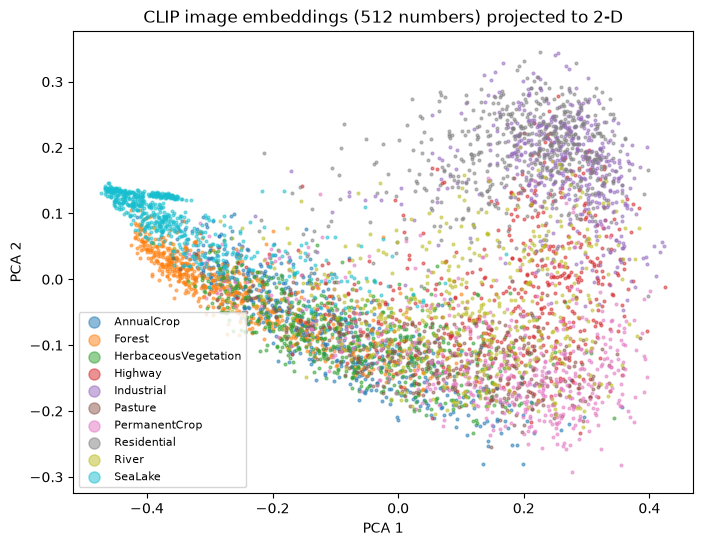

In [12]:
from sklearn.decomposition import PCA

xy = PCA(n_components=2, random_state=0).fit_transform(img_emb.numpy())
plt.figure(figsize=(8, 6))
for i, cls in enumerate(CLASSES):
    m = truth == i
    plt.scatter(xy[m, 0], xy[m, 1], s=4, alpha=0.5, label=cls, color=plt.cm.tab10(i))
plt.legend(markerscale=4, fontsize=8, loc="best")
plt.title("CLIP image embeddings (512 numbers) projected to 2-D")
plt.xlabel("PCA 1"); plt.ylabel("PCA 2")
plt.show()

## Part C: A decoder that writes (BLIP image captioning)

**BLIP** (Salesforce, 2022) is an **encoder–decoder** model:

1. its **image encoder** turns the image into a sequence of embeddings (one per image patch);
2. its **text decoder** then writes a caption **one word piece (token) at a time**. At every step it looks back at the
   image embeddings (through *cross-attention*) and at the words written so far, and predicts the most likely next token.

This is the same mechanism large language models use to generate text, just with an image as the starting context.

In [13]:
from transformers import BlipForConditionalGeneration, BlipProcessor

with timed("8. Load BLIP (download on first run)"):
    blip = BlipForConditionalGeneration.from_pretrained("Salesforce/blip-image-captioning-base").to(DEVICE).eval()
    blip_proc = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-base")

# One example per class, enlarged to the 384x384 pixels BLIP expects
examples = [eurosat.index[eurosat["label"] == c][0] for c in CLASSES]
example_imgs = [images[k].resize((384, 384), Image.BICUBIC) for k in examples]

inputs = blip_proc(images=example_imgs[:1], return_tensors="pt").to(DEVICE)
with torch.no_grad():
    patches = blip.vision_model(pixel_values=inputs["pixel_values"]).last_hidden_state
print(f"image pixels       : {tuple(inputs['pixel_values'].shape)}")
print(f"image embeddings   : {tuple(patches.shape)}  (24x24=576 patches + 1 summary, 768 numbers each)")
print("  -> the text decoder reads all 577 embeddings while it writes")

[time] 8. Load BLIP (download on first run): 2.2 s
image pixels       : (1, 3, 384, 384)
image embeddings   : (1, 577, 768)  (24x24=576 patches + 1 summary, 768 numbers each)
  -> the text decoder reads all 577 embeddings while it writes


In [14]:
# Watch the decoder write: caption the Forest image, then show the text growing token by token.
# The first steps are our starting phrase ("prompt"); after that, every token is chosen by the decoder.
forest = CLASSES.index("Forest")
with torch.no_grad():
    out = blip.generate(**blip_proc(images=example_imgs[forest:forest + 1], text="a satellite image of",
                                    return_tensors="pt").to(DEVICE), max_new_tokens=20)
tokens = out[0]
shown = ""
for k in range(1, len(tokens) + 1):
    text = blip_proc.decode(tokens[:k], skip_special_tokens=True)
    if text and text != shown:                    # skip invisible special tokens
        print(f"token {k:2d}: {text}")
        shown = text

token  2: a
token  3: a satellite
token  4: a satellite image
token  5: a satellite image of
token  6: a satellite image of a
token  7: a satellite image of a green
token  8: a satellite image of a green forest


[time] 9. BLIP: caption 10 images (with and without a starting phrase): 0.8 s


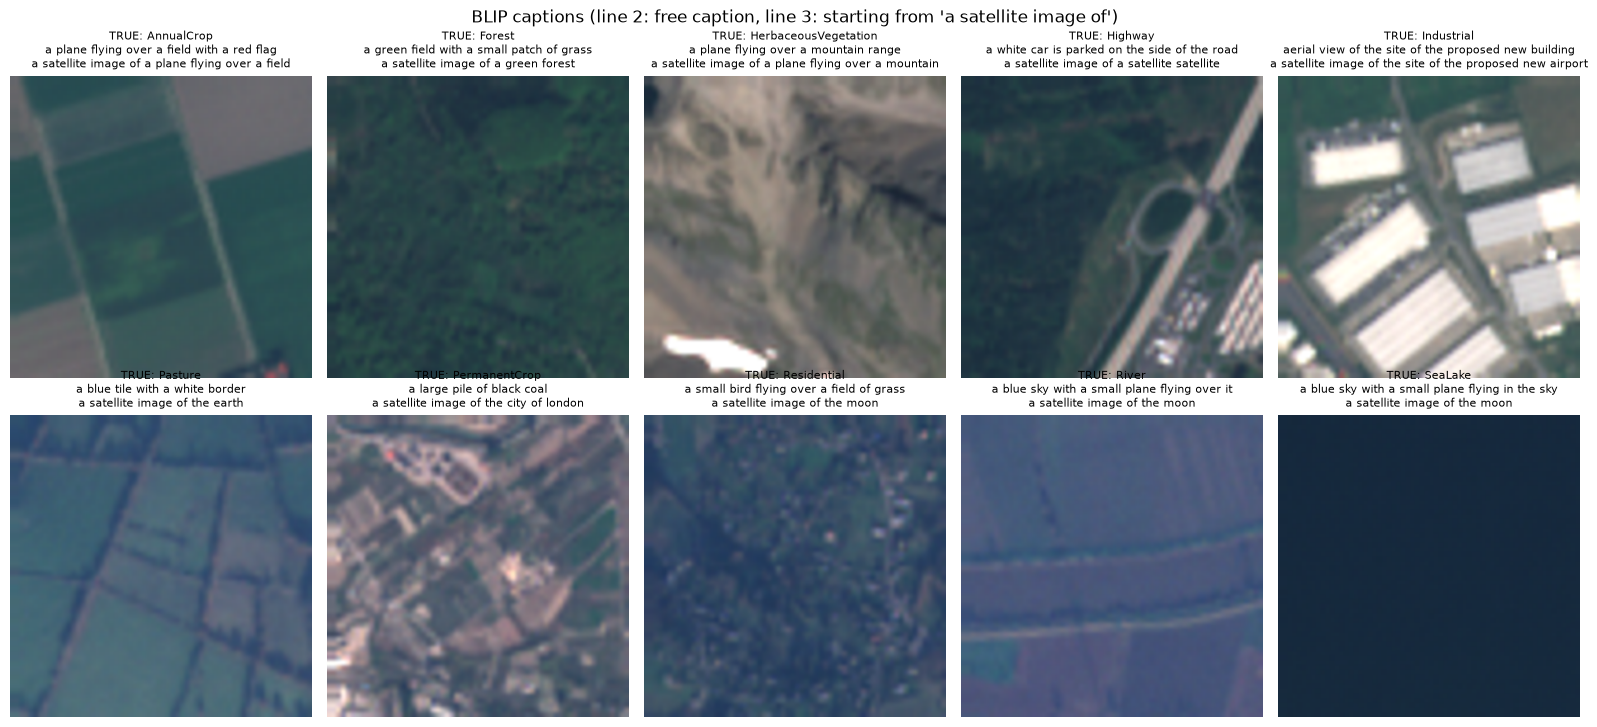

In [15]:
with timed("9. BLIP: caption 10 images (with and without a starting phrase)"):
    with torch.no_grad():
        free = blip.generate(**blip_proc(images=example_imgs, return_tensors="pt").to(DEVICE), max_new_tokens=20)
        guided = blip.generate(**blip_proc(images=example_imgs, text=["a satellite image of"] * len(example_imgs),
                                           return_tensors="pt").to(DEVICE), max_new_tokens=20)

fig, axes = plt.subplots(2, 5, figsize=(16, 7.5))
for ax, cls, img, f, g in zip(axes.flat, CLASSES, example_imgs, free, guided):
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"TRUE: {cls}\n{blip_proc.decode(f, skip_special_tokens=True)}\n"
                 f"{blip_proc.decode(g, skip_special_tokens=True)}", fontsize=8)
plt.suptitle("BLIP captions (line 2: free caption, line 3: starting from 'a satellite image of')")
plt.tight_layout()
plt.show()

**How to read the captions**

Most captions are wrong or funny (planes, the moon, a white car). This is not a bug, it is the most important lesson
about decoders: **a decoder can only produce what it learned from its training data.** BLIP was trained on everyday
photos with captions; it has hardly seen low-resolution satellite tiles, so it falls back on familiar phrases.
The text still sounds fluent, which is why generated output must always be checked.

Starting the caption with "a satellite image of" (a *prompt*) steers the decoder, but cannot add knowledge it does not have.
For urban-energy use, models trained on remote-sensing data (or fine-tuned on it) are needed.

## Summary

| | Part A: autoencoder | Part B: CLIP | Part C: BLIP |
| :--- | :--- | :--- | :--- |
| Input modality | load profile | image + text | image (+ text prompt) |
| Encoder(s) | 24 -> 2 numbers | image -> 512, text -> 512 | image -> 577 x 768 |
| Decoder | 2 -> 24 numbers | none | writes text token by token |
| Used for | compressing, generating profiles | comparing, zero-shot classification | captioning |

## Runtime summary

In [16]:
timing_table = pd.Series(TIMINGS, name="seconds").round(1).to_frame()
timing_table.loc["Total (timed steps)"] = timing_table["seconds"].sum().round(1)
gpu = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU only"
print(f"Hardware: {gpu}")
display(timing_table)
timing_table.assign(device=gpu).to_csv(CACHE / "module3_runtime.csv")

Hardware: Quadro RTX 6000


,seconds
1. Load electricity demand (download on first run),0.1
"2. Train autoencoder (3,000 steps)",11.4
3. Load EuroSAT images (download on first run),1.9
4. Load CLIP (download on first run),2.4
"5. CLIP: encode 5,400 images",21.3
6. CLIP: zero-shot classification (3 prompt templates),0.1
7. Linear probe on CLIP image embeddings,0.4
8. Load BLIP (download on first run),2.2
9. BLIP: caption 10 images (with and without a starting phrase),0.8
Total (timed steps),40.6


## Things to try

- **Part A:** set `EMBED_DIM = 4` or `8`. The reconstruction error drops, but you can no longer plot the embedding directly. Why is that a trade-off?
- **Part A:** remove the division by the daily mean, so the model sees absolute load. How does the embedding change?
- **Part B:** write better class descriptions (e.g. "an aerial view of a dense residential area"). Can you beat the best template?
- **Part B:** train the linear probe with only 10 labelled images per class. How much of the accuracy remains?
- **Part B:** encode the class sentences too and add them to the PCA plot. You will see the text embeddings far from all images:
  the known *modality gap* of CLIP. Similarity still works because only the *direction* of the vectors matters.
- **Part C:** caption your own photo of a building (`Image.open("my_photo.jpg")`). BLIP does much better on everyday photos.